In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [3]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Documents\\Spatial\\notebook'

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

## pt2_lesion ##

In [52]:
adata = sc.read ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt2_lesion_neighborhood_261009.h5ad')

In [54]:
adata

AnnData object with n_obs × n_vars = 9324 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'Section', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [56]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['JMlesion_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.2488718172741601
Gathering the latent weights


In [57]:
adata

AnnData object with n_obs × n_vars = 9324 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'Section', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## try k =6 ##

In [62]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=6, label='spatial_lda_kmeans6')

Kmeans clustering


In [79]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'goldenrod', '1':'lightsalmon', '2':'rosybrown', '3':'yellowgreen', '4':'olive','5' : 'purple'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans6', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt2_lesion_IC+kera_6clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt2_lesion_IC+kera_6clusters_261009.png


In [89]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt2_lesion_neighborhood_261009.h5ad')

In [91]:
adata

AnnData object with n_obs × n_vars = 9324 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'Section', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [93]:
adata.obs.imageid.unique()

['Pt2_lesion_proseq']
Categories (1, object): ['Pt2_lesion_proseq']

## Generate heatmap ##

In [3]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt2_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 9324 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'Section', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [4]:
adata.obs.imageid.unique()

['Pt2_lesion_proseq']
Categories (1, object): ['Pt2_lesion_proseq']

In [5]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_5596\545790267.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()


spatial_lda_kmeans6,0,1,2,3,4,5
Cell_label_L3,,,,,,
Basal keratinocyte_lesion,156,6,743,46,4,3
Basal keratinocyte_non-lesion,12,25,55,601,118,0
CD4 T cell_FOXP3+,9,149,12,38,3,18
CD4 T cell_GZMBhi,4,51,6,2,0,89
CD4 T cell_GZMBlow,0,1403,19,19,0,177
CD8 T cell_GZMBhi,15,183,66,16,3,133
CD8 T cell_GZMBlow,1,354,6,9,0,44
DC,1,28,11,10,0,12
DC_LAMP3+,2,100,14,0,0,116


In [6]:
frequency_table = (df / df.sum())*100
pd.options.display.float_format = '{:.2f}'.format

In [7]:
custom_order = ['0', '2', '5','1','4','3']
frequency_table = frequency_table[custom_order]

In [8]:
frequency_table.columns = ['N0','N1','N2','N3','N4', 'N5']
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
Basal keratinocyte_lesion,17.29,41.03,0.22,0.17,0.49,4.53
Basal keratinocyte_non-lesion,1.33,3.04,0.00,0.73,14.53,59.21
CD4 T cell_FOXP3+,1.00,0.66,1.33,4.34,0.37,3.74
CD4 T cell_GZMBhi,0.44,0.33,6.58,1.49,0.00,0.20
CD4 T cell_GZMBlow,0.00,1.05,13.08,40.89,0.00,1.87
CD8 T cell_GZMBhi,1.66,3.64,9.83,5.33,0.37,1.58
CD8 T cell_GZMBlow,0.11,0.33,3.25,10.32,0.00,0.89
DC,0.11,0.61,0.89,0.82,0.00,0.99
DC_LAMP3+,0.22,0.77,8.57,2.91,0.00,0.00


In [9]:
list2 = ['Supra keratinocyte_CXCL8+_2', 'Supra keratinocyte_CXCL8+_1', 'Basal keratinocyte_lesion',
         'Supra keratinocyte_KRT2+_2', 'Supra keratinocyte_KRT2+_1', 'Basal keratinocyte_non-lesion',
        'CD8 T cell_GZMBhi','CD4 T cell_GZMBhi','CD8 T cell_GZMBlow','CD4 T cell_GZMBlow','CD4 T cell_FOXP3+','NK cell','Plasmablast cell',
        'Mono_IL3RA+','Mono_ISGhi','Mac_IL3RA+', 'Mac_ISGhi', 'DC_LAMP3+','DC','PDC'
]

len(list2)

20

In [10]:
frequency_table.shape

(20, 6)

In [11]:
# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
Supra keratinocyte_CXCL8+_2,22.51,7.90,0.30,0.03,2.83,0.00
Supra keratinocyte_CXCL8+_1,43.02,7.90,0.00,0.00,0.49,1.28
Basal keratinocyte_lesion,17.29,41.03,0.22,0.17,0.49,4.53
Supra keratinocyte_KRT2+_2,1.11,3.09,0.00,0.00,26.35,0.00
Supra keratinocyte_KRT2+_1,3.22,0.17,0.00,0.00,51.60,7.09
Basal keratinocyte_non-lesion,1.33,3.04,0.00,0.73,14.53,59.21
CD8 T cell_GZMBhi,1.66,3.64,9.83,5.33,0.37,1.58
CD4 T cell_GZMBhi,0.44,0.33,6.58,1.49,0.00,0.20
CD8 T cell_GZMBlow,0.11,0.33,3.25,10.32,0.00,0.89


In [12]:
frequency_table.index = ['Granu kera_CXCL8+',
 'Spino kera_CXCL8+',
 'Basa kera_ulc',
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basa kera_adj',
 'CD8 T_GZMBhi',
 'CD4 T_GZMBhi',
 'CD8 T_GZMBlow',
 'CD4 T_GZMBlow',
 'CD4 T_FOXP3+',
 'NK',
  'Plasmablast',
 'Mono_IL3RA+',
 'Mono_ISGhi',
 'Mac_IL3RA+','Mac_ISGhi',
 'DC_LAMP3+',
 'DC',
 'PDC']
frequency_table

,N0,N1,N2,N3,N4,N5
Granu kera_CXCL8+,22.51,7.90,0.30,0.03,2.83,0.00
Spino kera_CXCL8+,43.02,7.90,0.00,0.00,0.49,1.28
Basa kera_ulc,17.29,41.03,0.22,0.17,0.49,4.53
Granu kera_KRT2+,1.11,3.09,0.00,0.00,26.35,0.00
Spino kera_KRT2+,3.22,0.17,0.00,0.00,51.60,7.09
Basa kera_adj,1.33,3.04,0.00,0.73,14.53,59.21
CD8 T_GZMBhi,1.66,3.64,9.83,5.33,0.37,1.58
CD4 T_GZMBhi,0.44,0.33,6.58,1.49,0.00,0.20
CD8 T_GZMBlow,0.11,0.33,3.25,10.32,0.00,0.89
CD4 T_GZMBlow,0.00,1.05,13.08,40.89,0.00,1.87


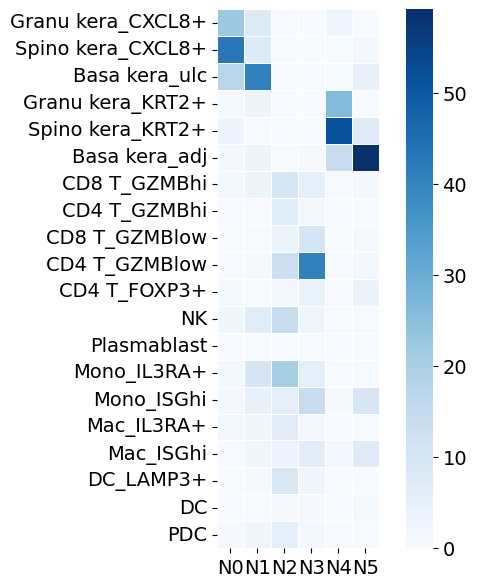

In [13]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()

In [14]:
adata.obs.imageid.unique()

['Pt2_lesion_proseq']
Categories (1, object): ['Pt2_lesion_proseq']